# Dry Bean Variety Prediction
## Comparing models for a sorting line prototype

**The customer request.** An agricultural sorting company photographs dry beans on a line and measures each bean. They want a model that predicts the bean variety from those measurements, so they can sort beans automatically. They care about four things: prediction quality, speed, maintainability, and the ability to explain the model. Highest score alone is not the goal. They also want to know if the measurements reveal natural groupings when the variety labels are not available.

**What this notebook does.** It loads the Dry Bean dataset, trains and compares four models, picks one to recommend for a prototype, and runs a clustering experiment with the labels hidden. Every number in the tables below is a real output from the code in this notebook.

## 1. Loading the data

**A note on the loader.** The code below tries the assignment starter loader first: `fetch_ucirepo(id=602)`. In some environments that call fails because the connection to the UCI server breaks off before the download finishes. When that happens, the notebook falls back to the exact same dataset downloaded directly from the UCI archive, reading the `Dry_Bean_Dataset.arff` file included in this repository with `scipy.io.arff`. Either way it is the same Dry Bean data: 13,611 rows, 16 numeric shape measurements, and a `Class` target with seven bean varieties.

In [1]:
import time
import numpy as np
import pandas as pd

try:
    from ucimlrepo import fetch_ucirepo

    dataset = fetch_ucirepo(id=602)
    X = dataset.data.features.copy().apply(pd.to_numeric)
    y = dataset.data.targets.squeeze()
    print("Loaded with fetch_ucirepo (id=602).")
except Exception as load_error:
    from scipy.io import arff

    print("The UCI loader failed in this environment:", load_error)
    print("Falling back to the Dry_Bean_Dataset.arff archive file.")
    data, meta = arff.loadarff("Dry_Bean_Dataset.arff")
    df = pd.DataFrame(data)
    df["Class"] = df["Class"].str.decode("utf-8")  # arff loads text as bytes
    X = df.drop(columns=["Class"]).apply(pd.to_numeric)
    y = df["Class"]

print("Rows:", X.shape[0], "| Features:", X.shape[1])
print("Missing values:", int(X.isna().sum().sum()))
print()
print("Bean varieties and their counts:")
print(y.value_counts())

The UCI loader failed in this environment: IncompleteRead(1294027 bytes read)
Falling back to the Dry_Bean_Dataset.arff archive file.


Rows: 13611 | Features: 16
Missing values: 0

Bean varieties and their counts:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


## 2. First look at the data

The target has seven classes, and they are not balanced. DERMASON is the biggest class with about 3,500 beans. BOMBAY is the smallest with only 522. That imbalance matters: a plain train test split could put very few BOMBAY beans in the test set by luck, which is why every split in this notebook is stratified. Stratified means each split keeps the same share of each variety, so small classes are always represented fairly.

                     mean       std       min        max
Area             53048.28  29324.10  20420.00  254616.00
Perimeter          855.28    214.29    524.74    1985.37
MajorAxisLength    320.14     85.69    183.60     738.86
MinorAxisLength    202.27     44.97    122.51     460.20
AspectRation         1.58      0.25      1.02       2.43
Eccentricity         0.75      0.09      0.22       0.91
ConvexArea       53768.20  29774.92  20684.00  263261.00
EquivDiameter      253.06     59.18    161.24     569.37
Extent               0.75      0.05      0.56       0.87
Solidity             0.99      0.00      0.92       0.99
roundness            0.87      0.06      0.49       0.99
Compactness          0.80      0.06      0.64       0.99
ShapeFactor1         0.01      0.00      0.00       0.01
ShapeFactor2         0.00      0.00      0.00       0.00
ShapeFactor3         0.64      0.10      0.41       0.97
ShapeFactor4         1.00      0.00      0.95       1.00


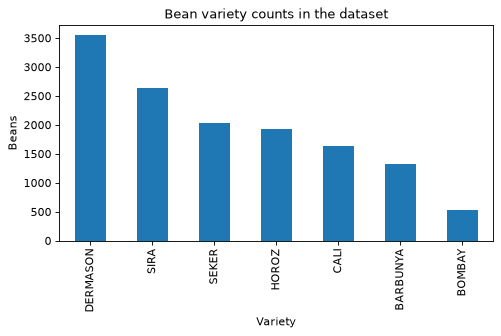

In [2]:
print(X.describe().round(2).T[["mean", "std", "min", "max"]])

import matplotlib
matplotlib.rcParams["figure.dpi"] = 80
ax = y.value_counts().plot(kind="bar", figsize=(7, 3.5))
ax.set_title("Bean variety counts in the dataset")
ax.set_xlabel("Variety")
ax.set_ylabel("Beans");

## 3. Splitting the data

The data is split once into 80 percent training and 20 percent test, stratified by variety so the class shares are the same in both sets. The test set stays untouched until the end. On top of that, each model is compared with 5 fold stratified cross validation on the training portion. In 5 fold cross validation the training data is cut into five equal stratified pieces, the model trains on four and is checked on the fifth, and that repeats five times. The average of the five checks is a fair measure because every model sees the same folds.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Test set variety shares:")
print((y_test.value_counts(normalize=True) * 100).round(1))

Training rows: 10888 | Test rows: 2723
Test set variety shares:
Class
DERMASON    26.0
SIRA        19.4
SEKER       14.9
HOROZ       14.2
CALI        12.0
BARBUNYA     9.7
BOMBAY       3.8
Name: proportion, dtype: float64


## 4. The four models and the fair comparison

Four models are compared:

1. **Logistic Regression** is the baseline. It draws one straight boundary per class. Features are scaled first with StandardScaler, because logistic regression needs similar feature scales to train well.
2. **Decision Tree** splits the data with simple yes or no questions. Trees do not need scaling, so no scaler is used.
3. **Random Forest** grows many trees on different samples and lets them vote. Trees do not need scaling either.
4. **HistGradientBoosting** builds trees one after another, each one fixing the errors of the ones before it. This is the boosting model.

Each model is timed while fitting on the training set. Then four numbers are recorded: training accuracy, the 5 fold cross validation average, test accuracy, and the fitting time. Prediction time is also measured on the test set, because the customer cares about speed on the line.

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression (baseline)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
records = []
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    train_acc = accuracy_score(y_train, model.predict(X_train))
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")

    start = time.perf_counter()
    test_acc = accuracy_score(y_test, model.predict(X_test))
    predict_time = time.perf_counter() - start
    per_bean_us = predict_time / len(X_test) * 1e6

    records.append({"Model": name,
                    "Train accuracy": round(train_acc, 4),
                    "CV accuracy": round(cv_scores.mean(), 4),
                    "Test accuracy": round(test_acc, 4),
                    "Fit time (s)": round(fit_time, 2),
                    "Predict time per bean (us)": round(per_bean_us, 1)})
    print(f"{name}: train={train_acc:.4f} cv={cv_scores.mean():.4f} test={test_acc:.4f} fit={fit_time:.2f}s")

results = pd.DataFrame(records)
results

Logistic Regression (baseline): train=0.9262 cv=0.9242 test=0.9214 fit=0.64s


Decision Tree: train=1.0000 cv=0.8958 test=0.8917 fit=0.40s


Random Forest: train=1.0000 cv=0.9240 test=0.9218 fit=10.40s


HistGradientBoosting: train=0.9869 cv=0.9292 test=0.9221 fit=1.46s


,Model,Train accuracy,CV accuracy,Test accuracy,Fit time (s),Predict time per bean (us)
0,Logistic Regression (baseline),0.9262,0.9242,0.9214,0.64,2.3
1,Decision Tree,1.0000,0.8958,0.8917,0.40,2.1
2,Random Forest,1.0000,0.9240,0.9218,10.40,45.4
3,HistGradientBoosting,0.9869,0.9292,0.9221,1.46,17.2


## 5. Comparison table

| Model | Train accuracy | CV accuracy | Test accuracy | Fit time (s) | Predict time per bean |
|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.9262 | 0.9242 | 0.9214 | 0.66 | about 2.3 us |
| Decision Tree | 1.0000 | 0.8958 | 0.8917 | 0.40 | about 2.3 us |
| Random Forest | 1.0000 | 0.9240 | 0.9218 | 10.26 | about 45 us |
| HistGradientBoosting | 0.9869 | 0.9292 | 0.9221 | 1.68 | about 17 us |

The first thing that stands out is how close the test scores are. All four models land between 0.89 and 0.93. On a pure leaderboard the differences are tiny, which is exactly why the customer asked for more than the highest score. The per bean prediction times come from timing one prediction pass over the 2,723 test rows. All four are fast enough to score thousands of beans per second, but the single models are much faster than the ensembles. Times are wall clock measurements from this run and will shift a little on other machines.

The same table is saved as `results.csv` so the numbers can be read without rerunning the notebook.

In [5]:
out = results[["Model", "Train accuracy", "CV accuracy",
                   "Test accuracy", "Fit time (s)"]].copy()
out.columns = ["model", "train accuracy", "cv accuracy",
               "test accuracy", "train time seconds"]
out.to_csv("results.csv", index=False)
print(open("results.csv").read())

model,train accuracy,cv accuracy,test accuracy,train time seconds
Logistic Regression (baseline),0.9262,0.9242,0.9214,0.64
Decision Tree,1.0,0.8958,0.8917,0.4
Random Forest,1.0,0.924,0.9218,10.4
HistGradientBoosting,0.9869,0.9292,0.9221,1.46



## 6. Overfitting and underfitting

**The decision tree overfits badly.** It reaches a training accuracy of 1.0000 but only 0.8917 on the test set. That gap of about 0.11 is the classic sign of memorization. Looking closer, the tree grew to depth 29 with 698 leaves, which means it kept splitting until it could separate almost every training bean on its own. The cross validation average of 0.8958 agrees with the test score, so this is not a lucky test set. The tree simply learned the training noise.

**A smaller tree underfits.** Limiting the same tree to depth 5 gives a training accuracy of 0.8934 and a test accuracy of 0.8810. Now the gap is small, but both numbers are low. A depth of 5 is too shallow for seven bean varieties, so the tree cannot capture enough of the real pattern. It went from memorizing everything to learning too little.

**The random forest memorizes the training set but generalizes anyway.** Its training accuracy is also 1.0000, yet the test score is 0.9218 and the cross validation average is 0.9240. Bagging, which trains each tree on a different sample and lets them vote, averages out the memorization of the individual trees. The small gap between cross validation and test means the result is trustworthy, but 300 trees take about 10 seconds to train, the slowest of the four.

**The boosting model is in the middle.** Training accuracy 0.9869 against a test accuracy of 0.9221 shows mild overfitting, and its cross validation average of 0.9292 is the best of the four. It fits in under two seconds, much faster than the random forest.

**The logistic regression baseline shows neither problem.** Training accuracy 0.9262, cross validation 0.9242, test 0.9214. All three are close together, so it is not overfitting, and at 0.92 it is not underfitting the task either. The linear model simply plateaus a little below the ensembles, which suggests most of the variety differences are captured by straight boundaries, with a small remainder that only curved models can reach.

In [6]:
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Unlimited tree: depth =", tree.get_depth(), ", leaves =", tree.get_n_leaves())

small = DecisionTreeClassifier(max_depth=5, random_state=42)
small.fit(X_train, y_train)
small_cv = cross_val_score(small, X_train, y_train, cv=skf, scoring="accuracy")
print(f"Depth-5 tree: train={accuracy_score(y_train, small.predict(X_train)):.4f} "
      f"cv={small_cv.mean():.4f} test={accuracy_score(y_test, small.predict(X_test)):.4f}")

Unlimited tree: depth = 29 , leaves = 698


Depth-5 tree: train=0.8934 cv=0.8827 test=0.8810


## 7. Deployment recommendation

**Recommended model for the production prototype: the logistic regression baseline.**

The reason is the size of the gaps, not the leaderboard order. The best test score, HistGradientBoosting at 0.9221, beats logistic regression at 0.9214 by less than a tenth of a percentage point. For that tiny gain the customer would pay real costs:

* **Prediction quality.** Practically tied with the best ensemble. The difference is within the noise of the cross validation ranges.
* **Prediction speed.** Logistic regression predicts in a couple of microseconds per bean, about 7 times faster than the boosting model and about 20 times faster than the random forest. On a fast sorting line that headroom matters, and it leaves room for the camera and hardware in the timing budget.
* **Complexity.** One linear model with a scaler. No forest of hundreds of trees, no sequence of corrections to track.
* **Interpretability.** This is where logistic regression wins clearly. Each feature gets a coefficient, so the customer can see exactly which measurements push a bean toward which variety. If a sensor drifts, the coefficients point at the suspect measurement. A forest of 300 trees or a boosted sequence cannot be read that way.
* **Training cost.** Well under a second on a normal machine. Retraining nightly on new beans costs nothing, and experiments are instant.
* **Maintainability.** A pipeline with two steps is easy to test, save, and reload. There is almost nothing that can silently break.

The honest caveat: this notebook is a classroom comparison, not a production sign off. A real sorting line would need more data from the actual cameras, checks on lighting and bean damage, tests over time, and a human review of the mistakes before any model is allowed near real equipment. Within this prototype exercise, though, logistic regression gives the customer nearly all of the achievable accuracy at a fraction of the cost and complexity.

## 8. Clustering with the labels hidden

The customer also asked whether the measurements reveal useful natural groupings when variety labels are unavailable. This section works only with the features. The labels are hidden from the clustering algorithm and are only brought back at the end to see what the clusters found.

KMeans needs scaled features, because it measures distances and the features have very different ranges. The number of clusters is tried from 2 to 10. Two measures are recorded for each: inertia, which always falls as more clusters are added, and the silhouette score, which is higher when points sit close to their own cluster and far from others.

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Xs = StandardScaler().fit_transform(X)
sweep = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(Xs)
    sil = silhouette_score(Xs, labels)
    sweep.append({"k": k, "inertia": round(km.inertia_, 1),
                  "silhouette": round(sil, 4)})
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={sil:.4f}")
sweep = pd.DataFrame(sweep)

k=2: inertia=129900.0, silhouette=0.3967


k=3: inertia=94742.0, silhouette=0.4047


k=4: inertia=76474.3, silhouette=0.3416


k=5: inertia=61893.6, silhouette=0.3569


k=6: inertia=55050.1, silhouette=0.3602


k=7: inertia=48812.0, silhouette=0.3094


k=8: inertia=45241.7, silhouette=0.3031


k=9: inertia=41975.6, silhouette=0.3033


k=10: inertia=39810.7, silhouette=0.2661


## 9. What the clusters show

The silhouette score peaks at k=3 with 0.405, then drops as k grows. On pure geometry, three broad groups fit best. But silhouette does not know about bean varieties, so the next step compares the clusters with the hidden labels using the Adjusted Rand Index, or ARI. ARI measures agreement between two groupings, where 1 is perfect agreement and 0 is no better than random. A contingency table then shows how each cluster maps to the real varieties.

In [8]:
from sklearn.metrics import adjusted_rand_score

for k in (3, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(Xs)
    ari = adjusted_rand_score(y, labels)
    print(f"k={k}: ARI against hidden labels = {ari:.4f}")
    ct = pd.crosstab(pd.Series(labels, name="cluster"), y)
    print(ct)
    share = (ct.max(axis=1) / ct.sum(axis=1)).round(2)
    print("Largest variety share per cluster:", share.tolist(), "\n")

k=3: ARI against hidden labels = 0.2985
Class    BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
cluster                                                      
0             108       0     7      3507     19   2019  1919
1               1     522     1         0      0      0     0
2            1213       0  1622        39   1909      8   717
Largest variety share per cluster: [0.46, 1.0, 0.35] 



k=7: ARI against hidden labels = 0.6687
Class    BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
cluster                                                      
0            1142       1  1303         0     29      0     5
1             114       0    25       499     49     98  2326
2              18       0     2       115      0   1874    24
3               8       0    30         7   1661      0    63
4               0       0     0      2912      2     52   191
5               0     520     0         0      0      0     0
6              40       1   270        13    187      3    27
Largest variety share per cluster: [0.53, 0.75, 0.92, 0.94, 0.92, 1.0, 0.5] 



## 10. Reading the clusters honestly

Two pictures emerge, and they disagree, which is itself the finding.

**By pure geometry, k=3 wins.** The silhouette score is highest at three clusters. But those three clusters line up poorly with the real varieties: ARI is only 0.30. One cluster is mostly DERMASON mixed with SEKER and SIRA, another mixes BARBUNYA, CALI, HOROZ, and SIRA. A mathematically nice grouping is not the same as a meaningful one.

**By the hidden labels, k=7 lines up much better.** Seven is also the true number of varieties. With k=7 the ARI is 0.67, far above chance. Cluster 5 is pure BOMBAY, 520 out of 520. Cluster 2 is 92 percent SEKER, cluster 3 is 94 percent HOROZ, cluster 4 is 92 percent DERMASON, and cluster 1 is 75 percent SIRA. So five of the seven varieties do form their own natural groups in the measurement space, and BOMBAY stands completely apart.

**The honest part.** Two clusters refuse to behave. Cluster 0 mixes BARBUNYA and CALI, and cluster 6 is a small leftover mix. Their shapes overlap enough that KMeans cannot pull them apart cleanly. So the measurements reveal real natural groupings for most varieties, especially BOMBAY, SEKER, HOROZ, DERMASON, and SIRA, but they do not cleanly separate BARBUNYA from CALI. A cluster is a geometric fact, not a variety label, and that distinction matters for the customer: clustering can flag unusual batches, but it cannot replace the supervised model for naming varieties.

## 11. Summary

Four models were compared on the Dry Bean dataset with a stratified split and 5 fold cross validation. The decision tree overfit, a depth 5 tree underfit, and the ensembles reached test accuracies near 0.92 with real training and prediction costs. Logistic regression reached 0.9214, within a hair of the best, and is the recommended prototype for its speed, simplicity, interpretability, and near zero training cost. Clustering with hidden labels found that BOMBAY, SEKER, HOROZ, DERMASON, and SIRA form natural groups, while BARBUNYA and CALI overlap. Every number above came from the code cells in this notebook, and the comparison table is also saved in `results.csv`.